# Sequence alignment and affinity distributions

The alignment table shades each of the ten selected residues per library by its
background-averaged change in binding affinity, split diagonally by antigen. The distribution figure plots every genotype's CH505TF affinity against its SF162 affinity for all nine libraries, with marginal histograms and the germline and mature genotypes marked.


### **House Keeping**

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.patheffects as PathEffects
from matplotlib.patches import FancyArrowPatch
import scipy as sp
import seaborn as sns
import numpy as np
import pandas as pd
import random
import os
import string
import re
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.stats.multitest import multipletests


In [ ]:
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

In [ ]:
###### Geneerate Label Assignment And Conversion Methods based on the Meta_Df
IMGT_column = 'imgt_position'
Kabat_column = 'kabat_position'
sites_column = 'site'
germline_col = 'germline_aa'
mature_col = 'mature_aa'

### Generates mapping for G#M notation (germline identity)+(Position #)+(mature identity)
def mutation_convert_label(meta_in,
                           position_col = Kabat_column,
                           sites_col = sites_column,
                           g_col = germline_col,
                           m_col = mature_col):
  mapping = {}
  for row, site in enumerate(meta_in[sites_col].values):
    mapping[f'{site}'] = f'{meta_in.loc[row,f'{g_col}']}{meta_in.loc[row,f'{position_col}']}{meta_in.loc[row,f'{m_col}']}'
  return mapping

In [ ]:
data_dir = "../data"
fig_dir = "../figures"
table_dir = "../tables"
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(table_dir, exist_ok=True)
png_dpi = 300

plt.rcParams["svg.fonttype"] = "path"   # illustrator drops live text, see the project export note
plt.rcParams["pdf.fonttype"] = 42

bnAb_list = ['1NC9','CH235.12','N49P7','NIH45-46','VRC-PG20','VRC01','VRC07','VRC13','VRC16']

# display name to file stem; the hyphens and the dot do not appear in any filename
name_to_stem = {'1NC9':'1NC9','CH235.12':'CH235_12','N49P7':'N49P7','NIH45-46':'NIH4546',
                'VRC-PG20':'VRCPG20','VRC01':'VRC01','VRC07':'VRC07','VRC13':'VRC13',
                'VRC16':'VRC16'}

rep_avg_cols = ['id','vh_aa'] + [f'site_{i}' for i in range(10)] + ['antigen']


def save_figure(stem):
    """Write the current figure to png, pdf and svg, then check the svg has no live text."""
    name = re.sub(r"[^A-Za-z0-9._-]+", "_", stem).strip("_")
    path = f"{fig_dir}/{name}"
    plt.savefig(f"{path}.png", dpi=png_dpi, bbox_inches="tight")
    plt.savefig(f"{path}.pdf", bbox_inches="tight")
    plt.savefig(f"{path}.svg", bbox_inches="tight")
    assert open(f"{path}.svg").read().count("<text") == 0, "live text in svg, check svg.fonttype"


kds_dict = {}; kds_dict_rep_avg = {}; meta_dict = {}
CH_all_dict = {}; SF_all_dict = {}; CH_params_dict = {}; SF_params_dict = {}
for name in bnAb_list:
    stem = name_to_stem[name]
    kds = pd.read_csv(f"{data_dir}/{stem}_kds.csv")
    kds_dict[name] = kds
    kds_dict_rep_avg[name] = kds.groupby(by=rep_avg_cols).agg({'nlog10_Kd':'mean'}).reset_index()
    meta_dict[name] = pd.read_csv(f"{data_dir}/{stem}_meta.csv")
    CH_all_dict[name] = pd.read_csv(f"{data_dir}/{stem}_CH505TF_BEST_df_all.csv")
    SF_all_dict[name] = pd.read_csv(f"{data_dir}/{stem}_SF162_BEST_df_all.csv")
    CH_params_dict[name] = pd.read_csv(f"{data_dir}/{stem}_CH505TF_BEST_df_params.csv")
    SF_params_dict[name] = pd.read_csv(f"{data_dir}/{stem}_SF162_BEST_df_params.csv")

In [ ]:
display(kds_dict.keys())

dict_keys(['1NC9', 'CH235.12', 'N49P7', 'NIH45-46', 'VRC-PG20', 'VRC01', 'VRC07', 'VRC13', 'VRC16'])

In [ ]:
heavychain_seq = pd.read_csv(f"{data_dir}/heavychain_mature_sequences.csv")
kabatsomatic_seq = pd.read_csv(f"{data_dir}/kabat_numbered_somatics.csv")
kabatgermline_seq = pd.read_csv(f"{data_dir}/kabat_numbered_germlines.csv")
p_values_updated = pd.read_csv(f"{data_dir}/site_stats.csv")
p_values_updated

,bnAb,Site Label (Kabat),CH505TF,SF162
0,1NC9,E10Q,0.0166,0.0000
1,1NC9,K19T,0.0000,0.0000
2,1NC9,M34I,0.0000,0.0001
3,1NC9,N52D,0.0000,0.0000
4,1NC9,S53R,0.0000,0.0000
...,...,...,...,...
85,VRC16,N73H,0.0000,0.0000
86,VRC16,N76D,0.0373,0.2028
87,VRC16,R83T,0.0303,0.0000
88,VRC16,A84V,0.6078,0.7013


### **Magna Magna Carta**

In [ ]:
kabat_mseq = kabatsomatic_seq['Name'].values
bnab_names = [name.split('_')[2] for name in kabat_mseq]
bnab_names
heavy_somatic = {}
heavy_germline = {}
combined_seq = {}

bnab_names = kabatsomatic_seq['Name'].values
bnab_names = [name.split('_')[2] for name in kabat_mseq]

def removed_blank(arr):
    removal_l = []
    for col in range(arr.shape[1]):
      if arr[1,col] == '-':
        removal_l.append(col)
    return arr[:,[x for x in range(arr.shape[1]) if x not in removal_l]]

def get_seq_arr(df,bnab_name,cut_filter):
  seq = df.loc[df['Name'].str.contains(bnab_name)].iloc[:,cut_filter:]
  pos_seq = np.zeros([2,len(seq.columns)],dtype = object)
  pos_seq[0,:] = seq.columns.values
  pos_seq[1,:] = seq.iloc[0,:].values
  return pos_seq

def natural_sort_key(s):
    # Splits the string by digits, converting digit blocks into integers
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', s)]

def get_numeric_col_value(col_str):
  if col_str == '35E':
    return 35.0
  elif col_str == '82B':
    return 82.0
  else:
    # Attempt to convert to float
    return float(col_str)

## acquire positions with a residue for each antibody
for names in bnab_names:

  somatic_pos_seq = get_seq_arr(kabatsomatic_seq,names,2) # get seq for somatic
  germline_pos_seq = get_seq_arr(kabatgermline_seq,names,5) # get seq for germline

  somatic_cleaned = removed_blank(somatic_pos_seq) # drop '-'
  germline_cleaned = removed_blank(germline_pos_seq)
  combined_positions = []
  combined_positions.extend(list(somatic_cleaned[0,:]))
  combined_positions.extend(list(germline_cleaned[0,:]))

  # condense the list to remove duplicates while showing sites that appear in at least one of the sequences
  combined_positions = set(combined_positions)
  combined_positions = sorted(combined_positions, key = natural_sort_key)

  heavy_somatic[names] = somatic_cleaned
  heavy_germline[names] = germline_cleaned
  combined_seq[names] = combined_positions

# get a master list for all positions for all the bnabs
all_bnab_l = []
for seq in combined_seq.values():
  all_bnab_l.extend(list(seq))
all_bnab_l = set(all_bnab_l)
all_bnab_l = sorted(all_bnab_l, key = natural_sort_key)

# get a master list for all positions altered in the experiment
modified_sites_l = []
for meta in meta_dict.values():
  modified_sites_l.extend([str(pos) for pos in meta['kabat_position'].values])

modified_sites_l = set(modified_sites_l)
modified_sites_l = sorted(modified_sites_l, key = natural_sort_key)

# identify gaps
modified_gap_filled = [] # initialize new list that has gaps filled with positions or ...
for idx in range(len(modified_sites_l)):
  current_site = modified_sites_l[idx]
  modified_gap_filled.append(current_site) # append current site

  if idx < len(modified_sites_l)-1:
    # when we are not at the last residue,
    next_site = modified_sites_l[idx+1] # identify the next site on the list
    difference = get_numeric_col_value(next_site) - get_numeric_col_value(current_site) #compute difference

    if difference == 2: # if the sites have one residue gap, fill it up.
      to_insert_idx = all_bnab_l.index(current_site)
      modified_gap_filled.append(all_bnab_l[to_insert_idx+1])
    elif difference > 2: #otherwise, insert '...'
      modified_gap_filled.append('...')

In [ ]:
# call empty df with columns as the list with '...' and filled gaps and index as bnabs
full_df = pd.DataFrame('-', columns = modified_gap_filled,index = sorted(combined_seq.keys()))

for i , col in enumerate(full_df.columns.values):
  if col == '...': #insert '...' into all rows of '...' columns
    full_df.iloc[:,i] = '...'

# copy out df for germline and mature seq
germline_df = full_df.copy()
somatic_df = full_df.copy()

# iterate over antibodies, then go through each site in the dataframe and load the residue for the site for each antibody.
for bnab_row in germline_df.index:
  for col in germline_df.columns:

    if col != '...':
      row_germline = kabatgermline_seq.loc[kabatgermline_seq['Name'].str.contains(bnab_row)].reset_index()
      germline_df.loc[bnab_row,col] = row_germline.loc[0,col]
# repeat for somatic seq
for bnab_row in somatic_df.index:
  for col in somatic_df.columns:
    if col != '...':
      row_somatic = kabatsomatic_seq.loc[kabatsomatic_seq['Name'].str.contains(bnab_row)].reset_index()
      somatic_df.loc[bnab_row,col] = row_somatic.loc[0,col]

# intialize empty df with  columns as the germline df columns and index with germline seq for bnab classes and the bnabs.
merged_df = pd.DataFrame('-', columns = germline_df.columns, index = ['VH1-46 Germline','1NC9','CH235.12',
                                                                     'VH1-2 Germline', 'N49P7','NIH45-46','VRC-PG20','VRC01','VRC07',
                                                                     'VRC13 Germline', 'VRC13','VRC16 Germline','VRC16'])

# fill in the germline for each class or bnab(for CDRH3)
merged_df.loc['VH1-46 Germline'] = germline_df.loc['1NC9'].values
merged_df.loc['VH1-2 Germline'] = germline_df.loc['N49P7'].values
merged_df.loc['VRC13 Germline'] = germline_df.loc['VRC13'].values
merged_df.loc['VRC16 Germline'] = germline_df.loc['VRC16'].values

# upload the bnab mature seq to the merged df
for bnab_row in merged_df.index:
  if bnab_row in somatic_df.index:
    merged_df.loc[bnab_row] = somatic_df.loc[bnab_row].values

merged_df.reset_index(inplace= True)
merged_df.rename(columns = {'index':'bnAb'},inplace = True)

In [ ]:
merged_df

,bnAb,3,...,10,11,...,16,17,18,19,...,84,85,...,91,92,93,...,108,109,110
0,VH1-46 Germline,Q,...,E,V,...,A,S,V,K,...,S,E,...,Y,C,A,...,-,-,-
1,1NC9,R,...,Q,L,...,A,S,V,T,...,G,D,...,Y,C,A,...,L,I,T
2,CH235.12,R,...,G,V,...,A,T,M,T,...,Y,D,...,Y,C,V,...,P,V,I
3,VH1-2 Germline,Q,...,E,V,...,A,S,V,K,...,S,D,...,Y,C,A,...,-,-,-
4,N49P7,D,...,V,V,...,D,S,V,R,...,S,D,...,Y,C,V,...,A,V,T
5,NIH45-46,R,...,Q,M,...,E,S,M,R,...,S,D,...,F,C,T,...,P,V,T
6,VRC-PG20,H,...,E,M,...,A,S,V,R,...,F,A,...,F,C,A,...,R,I,I
7,VRC01,Q,...,Q,M,...,E,S,M,R,...,V,D,...,F,C,T,...,P,V,I
8,VRC07,R,...,Q,M,...,D,S,M,R,...,S,D,...,F,C,T,...,P,V,T
9,VRC13 Germline,Q,...,E,V,...,S,S,V,K,...,S,E,...,Y,C,A,...,-,-,-


In [ ]:
#### Generate Data
def token_kds(bnab: str,antigen: str = None):
  '''''
  Creates a Dataframe with the Gtype +RAW Kd

  bnab = 'bnab name'

  antigen = 'CH505TF' or 'SF162' depending on which antigen you want

  '''''
  df = kds_dict_rep_avg[bnab]
  if antigen == 'CH505TF':
    df = df[df['antigen'] == antigen].copy()
  elif antigen == 'SF162':
    df = df[df['antigen'] == antigen].copy()
  else:
    pass

  df['genotype_tokens'] = df[['site_0','site_1','site_2','site_3','site_4','site_5','site_6','site_7','site_8','site_9']].agg(''.join, axis=1)
  df['n_somatic'] = ((df['site_0'] == 'M').astype(int) + (df['site_1'] == 'M').astype(int) + (df['site_2'] == 'M').astype(int) +
                               (df['site_3'] == 'M').astype(int) + (df['site_4'] == 'M').astype(int) + (df['site_5'] == 'M').astype(int) +
                               (df['site_6'] == 'M').astype(int) + (df['site_7'] == 'M').astype(int) + (df['site_8'] == 'M').astype(int) +
                               (df['site_9'] == 'M').astype(int) )


  return df

kds_token_dict_rep_avg = {}
for bnab in kds_dict_rep_avg.keys():
  for antigen in ['CH505TF','SF162']:

    kds_token_dict_rep_avg[f'{bnab}_{antigen}'] = token_kds(bnab, antigen = antigen)


site_effect_raw_dict = { }
raw_splot_dict = {}
site_effect = pd.DataFrame({
    'bnAb': kds_token_dict_rep_avg.keys()})
site_effect = site_effect.assign(
    site_0 = np.nan, site_1 = np.nan, site_2 = np.nan,
    site_3 = np.nan, site_4 = np.nan, site_5 = np.nan,
    site_6 = np.nan, site_7 = np.nan, site_8 = np.nan,
    site_9 = np.nan)

for bnab_ant, df_antigen in kds_token_dict_rep_avg.items():
    antigen = bnab_ant.split('_')[1]
    bnab = bnab_ant.split('_')[0]

    for s in range(10): # Loop through each site
        # Filter for germline variants at the current site 's'
        germline_s_df = df_antigen[df_antigen[f'site_{s}'] == 'G'].copy()

        if not germline_s_df.empty:
            # Create a new column with the genotype_tokens if site 's' was mature
            germline_s_df['mature_genotype_token'] = germline_s_df['genotype_tokens'].apply(
                lambda gtype: gtype[:s] + 'M' + gtype[s+1:]
            )

            # Merge to get the nlog10_Kd of the corresponding mature variant
            kds_merged_df = germline_s_df.merge(
                df_antigen[['genotype_tokens', 'nlog10_Kd']],
                left_on='mature_genotype_token',
                right_on='genotype_tokens',
                how='left',
                suffixes=('_germline', '_mature')
            )

            # Calculate the difference: mature_Kd - germline_Kd
            # This is the effect of changing site 's' from G to M
            kds_merged_df['difference'] = kds_merged_df['nlog10_Kd_mature'] - kds_merged_df['nlog10_Kd_germline']

            site_effect_raw_dict[f'{bnab}_{antigen}_site_{s}'] = kds_merged_df['difference'].values

            raw_splot_dict[f'{bnab}_{antigen}_site_{s}'] = np.array([kds_merged_df['nlog10_Kd_mature'].values,kds_merged_df['nlog10_Kd_germline'].values])



            # Calculate the average effect
            bg_avg_effect = kds_merged_df['difference'].mean()
        else:
            bg_avg_effect = np.nan # If no germline variants at this site, effect is NaN

        # Update the site_effect DataFrame
        site_effect_row_idx = site_effect.index[site_effect['bnAb'] == bnab_ant].tolist()
        if site_effect_row_idx:
            site_effect.loc[site_effect_row_idx[0], f'site_{s}'] = bg_avg_effect

site_effect['antigen'] = site_effect['bnAb'].apply(lambda x: x.split('_')[1])
site_effect['bnAb'] = site_effect['bnAb'].apply(lambda x: x.split('_')[0])

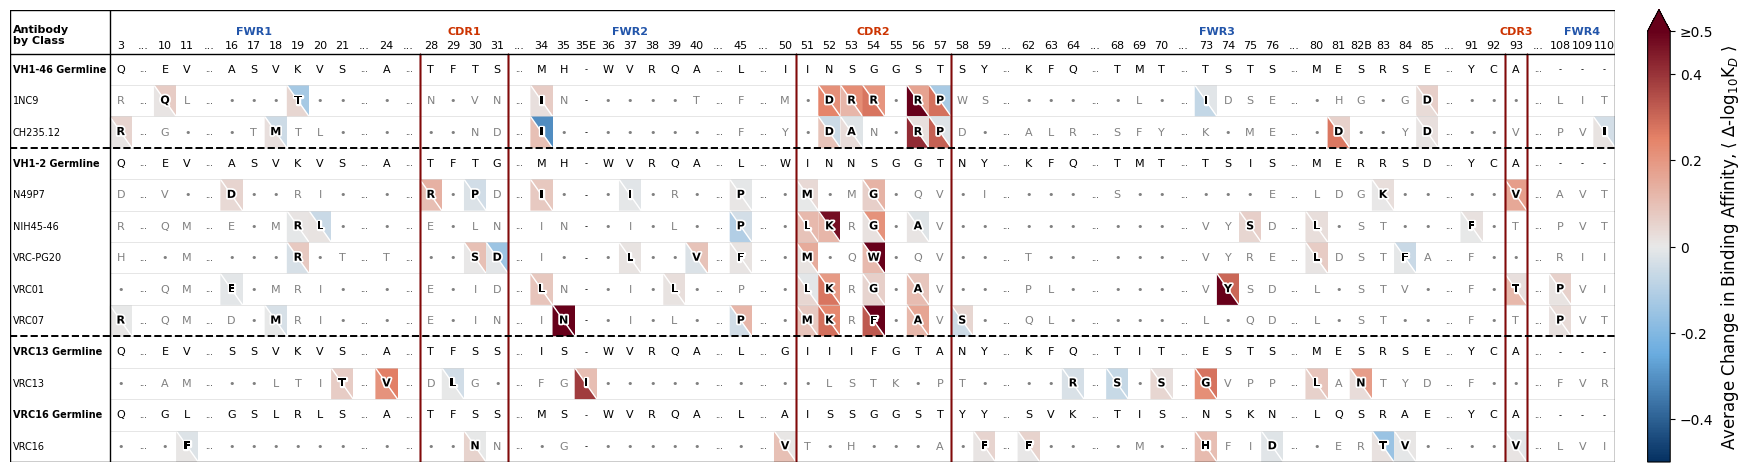

In [ ]:


# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
df = merged_df.copy()

LABEL_COL = df.columns[0]     # 'bnAb'
pos_cols = list(df.columns[1:])   # Kabat-numbered position columns

n_rows = len(df)
n_cols = len(pos_cols)


# ── Colour palette (publication style) ─────────────────────────────────────
COLOR_FW   = "#2255AA"   # framework labels
COLOR_CDR  = "#CC3300"   # CDR labels
COLOR_MUT  = "#882255"   # somatic mutations
COLOR_LINE = "#333333"   # region bracket lines
BG_CDR     = "#FFF3F0"   # very light salmon tint under CDR regions
FONT_MONO  = "DejaVu Sans Mono"
# –– Load Cmap –––––––––––––––––––––––––––––––––––––––––––––––––––––––––––––
# Calculate the global min and max for consistent colormap scaling across all heatmaps
all_site_effect_values = site_effect.filter(regex='site_\\d').values
# global_min_val = np.nanmin(all_site_effect_values)
# global_max_val = np.nanmax(all_site_effect_values)
# print(global_min_val, global_max_val) # these are the lowest and highest background average ∆Kd

# global_max_val = global_max_val - .2 # force down to improve color resolution
# # initialize colormap for the whole plot
# center = 0
# vrange = max(global_max_val - center, center - global_min_val)
# center_normalize = Normalize(center - vrange, center + vrange)
# cmin, cmax = center_normalize([global_min_val, global_max_val])
# cell_norm = Normalize(vmin=global_min_val, vmax=global_max_val) # normalization for coloring asterisks


##### adjusted loading
# –– Load Cmap –––––––––––––––––––––––––––––––––––––––––––––––––––––––––––––
# Fixed symmetrical range for the colormap and colorbar
global_min_val = -0.5
global_max_val = 0.5

# initialize colormap for the whole plot
center = 0
vrange = max(global_max_val - center, center - global_min_val)  # = 0.5
center_normalize = Normalize(center - vrange, center + vrange)   # Normalize(-0.5, 0.5)
cmin, cmax = center_normalize([global_min_val, global_max_val])  # -> [0.0, 1.0]
cell_norm = Normalize(vmin=global_min_val, vmax=global_max_val)  # normalization for colori



modified_coolwarm = LinearSegmentedColormap.from_list('my gradient', (
    # Edit this gradient at https://eltos.github.io/gradient/#053061-6AACE0-DFDFDE-E58368-67001A
    (0.000, (0.020, 0.188, 0.380)),
    (0.250, (0.416, 0.675, 0.878)),
    (0.500, (0.910, 0.910, 0.910)),
    (0.750, (0.898, 0.514, 0.408)),
    (1.000, (0.404, 0.000, 0.102))))


base_cmap = plt.get_cmap(modified_coolwarm)
trimmed_colors = base_cmap(np.linspace(cmin, cmax, 256))
trimmed_cmap = mpl.colors.ListedColormap(trimmed_colors)

# ----------------------------------------------------------------------
# 2. Region definitions (Kabat numbering) and colors
# ----------------------------------------------------------------------
FWR_REGIONS = [
    ("FWR1", 3, 24),
    ("FWR2", 30, 50),
    ("FWR3", 58, 91),
    ("FWR4", 108, 110),
]
CDR_REGIONS = [
    ("CDR1", 28, 31),
    ("CDR2", 51, 57),
    ("CDR3", 93, 93),
]

CDR_COLOR = "#F3F3F3"   # pastel red
FWR_COLOR = "#F3F3F3"   # white
UNKNOWN_COLOR = "#F3F3F3"  # columns whose Kabat number can't be determined (e.g. "...")


def region_of(col_name):
    """Map a Kabat position column (e.g. '35E', '82B') to a region name.
    FWR ranges are applied first, then CDR ranges override on overlap,
    so CDR boundaries always win."""
    match = re.match(r"(\d+)", str(col_name))
    if not match:
        return None  # e.g. literal '...' gap columns -> unknown region
    num = int(match.group(1))
    region = None
    for name, lo, hi in FWR_REGIONS:
        if lo <= num <= hi:
            region = name
    for name, lo, hi in CDR_REGIONS:
        if lo <= num <= hi:
            region = name
    return region


col_region = {c: region_of(c) for c in pos_cols}


def color_for_region(region):
    if region is None:
        return UNKNOWN_COLOR
    return CDR_COLOR if region.startswith("CDR") else FWR_COLOR


col_color = {c: color_for_region(col_region[c]) for c in pos_cols}

# ----------------------------------------------------------------------
# 3. Figure geometry
# ----------------------------------------------------------------------
cell_w, cell_h = .8, 1.0
label_w = 3.6   # reserved width for the bnAb name column
band_h = 1.4      # height of the top region-label band
fig_left_end = 0

fig_w = label_w + n_cols * cell_w
fig_h = band_h + n_rows * cell_h

fig, ax = plt.subplots(figsize=(fig_w * 0.30, fig_h * 0.32),layout = 'constrained')
ax.set_xlim(fig_left_end, fig_w)
ax.set_ylim(0, fig_h)
ax.invert_yaxis()
ax.axis("off")

# ----------------------------------------------------------------------
# 4. Column background shading behind the sequence grid
# ----------------------------------------------------------------------
# for j, col in enumerate(pos_cols):
#     x = label_w + j * cell_w
#     ax.add_patch(
#         patches.Rectangle(
#             (x, band_h), cell_w, n_rows * cell_h,
#             facecolor=col_color[col], edgecolor="none", zorder=0,
#         )
#     )


# ----------------------------------------------------------------------
# 5. Region labels across the top (merge consecutive same-region cols)
#    -- plain text only, no enclosing box/border
# ----------------------------------------------------------------------

# Helper function to get numeric value of a column, handling special cases and '...'
def get_numeric_col_value_for_region_span(col_str):
    if col_str == '35E':
        return 35.0
    elif col_str == '82B':
        return 82.0
    elif col_str == '...':
        return -9999 # A value that will not fall into any valid region range
    else:
        match = re.match(r"(\d+)", str(col_str))
        if match:
            return float(match.group(1))
        return -9999 # Default for unparseable strings

all_regions_to_plot = FWR_REGIONS + CDR_REGIONS

for region_name, region_start, region_end in all_regions_to_plot:
    first_col_idx = -1
    last_col_idx = -1

    for idx, col_name in enumerate(pos_cols):
        num_val = get_numeric_col_value_for_region_span(col_name)
        if region_start <= num_val <= region_end:
            if first_col_idx == -1:
                first_col_idx = idx
            last_col_idx = idx

    if first_col_idx != -1: # if at least one column for this region was found
        x_start_plot = label_w + first_col_idx * cell_w
        x_end_plot = label_w + (last_col_idx + 1) * cell_w # +1 to get the end of the last cell
        center_x = (x_start_plot + x_end_plot) / 2

        ax.text(
            center_x, band_h / 2, region_name,
            ha="center", va="center", fontsize=8, fontweight="bold",
            color=COLOR_FW if region_name.startswith('FWR') else COLOR_CDR # Use defined colors
        )

# Kabat position numbers, printed vertically just under the region band
for j, col in enumerate(pos_cols):
    x = label_w + j * cell_w + cell_w / 2
    ax.text(x, band_h - 0.1, str(col), ha="center", va="bottom", fontsize=8)

# ----------------------------------------------------------------------
# 6. Sequence grid: row labels + amino-acid letters
# ----------------------------------------------------------------------
for i in range(n_rows):
    y = band_h + i * cell_h + cell_h / 2
    row_label = df.iloc[i][LABEL_COL]
    is_diff_row = 'germline' not in row_label.lower()
    ax.text(
        0.1, y, row_label, ha="left", va="center",
        fontsize=7, fontstyle= 'normal',
        fontweight=("normal" if is_diff_row else "bold")    )

    for j, col in enumerate(pos_cols):
        x = label_w + j * cell_w + cell_w / 2
        xpatch_coor = label_w + j * cell_w
        ypatch_coor = band_h + i * cell_h
        # Use iloc with j+1 to get the scalar value, as col can be duplicated
        if is_diff_row:
          bnab = row_label
        else:
          bnab = False
        aa = df.iloc[i, j+1]
        if aa not in [ '-', '...']:
          if bnab:
            # call altered position as list of 10 letters
            altered_pos = [str(pos) for pos in meta_dict[bnab]['kabat_position'].values]

            # site_effect bg average values for this bnab
            bnab_effect = site_effect[site_effect['bnAb'] == bnab].copy()

            if col in altered_pos: # if the current col is in the altered_pos,
              txt = ax.text(x, y, str(aa), ha="center", va="center", fontsize=8, weight = ('bold' if is_diff_row else None),
                        color = ('k' if is_diff_row else 'green'))

              txt.set_path_effects([PathEffects.withStroke(linewidth=2.5, foreground="white")])
              ### generate patch color
              # load cmap colors
              site_num = altered_pos.index(col)
              d_point_CH505TF = bnab_effect[bnab_effect['antigen'] == 'CH505TF'][f'site_{site_num}'].values[0]
              d_point_SF162 = bnab_effect[bnab_effect['antigen'] == 'SF162'][f'site_{site_num}'].values[0]

              # generate CH505TF
              CH505TF_color = trimmed_cmap(cell_norm(d_point_CH505TF))
              CH505TFvertices = [(xpatch_coor, ypatch_coor), (xpatch_coor+cell_w, ypatch_coor+cell_h), (xpatch_coor, ypatch_coor+cell_h)]
              CH505TF_triangle = patches.Polygon(CH505TFvertices, closed=True, facecolor= CH505TF_color, edgecolor="blue", linewidth=0,zorder = 1)
              ax.add_patch(CH505TF_triangle)
              # generate SF162
              SF162_color = trimmed_cmap(cell_norm(d_point_SF162))
              SF162vertices = [(xpatch_coor, ypatch_coor), (xpatch_coor+cell_w, ypatch_coor), (xpatch_coor+cell_w, ypatch_coor+cell_h)]
              SF162_triangle = patches.Polygon(SF162vertices, closed=True, facecolor= SF162_color, edgecolor="blue", linewidth=0,zorder = 1)
              ax.add_patch(SF162_triangle)
              # plot diagnoal line for clarity
              ax.plot([xpatch_coor,xpatch_coor+cell_w], [ypatch_coor, ypatch_coor+cell_h], color = 'white', linewidth = 1,zorder = 1)

            else:
              dot_plot = False
              if row_label in ['1NC9', 'CH235.12']:
                if str(aa) == df.loc[0,col]:
                  ax.text(x, y, "•", ha="center", va="center", fontsize=8, weight = 'normal',
                            color = '#808080')
                else:
                  ax.text(x, y, str(aa), ha="center", va="center", fontsize=8, weight = 'normal',
                  color = '#808080')

              elif row_label in ['VRC01', 'VRC07','VRC-PG20','N49P7','NIH45-46']:
                if str(aa) == df.loc[3,col]:
                  ax.text(x, y, "•", ha="center", va="center", fontsize=8, weight = 'normal',
                            color = '#808080')
                else:
                  ax.text(x, y, str(aa), ha="center", va="center", fontsize=8, weight = 'normal',
                  color = '#808080')

              elif row_label == 'VRC13':
                if str(aa) == df.loc[9,col]:
                  ax.text(x, y, "•", ha="center", va="center", fontsize=8, weight = 'normal',
                            color = '#808080')
                else:
                  ax.text(x, y, str(aa), ha="center", va="center", fontsize=8, weight = 'normal',
                  color = '#808080')

              elif row_label =='VRC16':
                if str(aa) == df.loc[11,col]:
                  ax.text(x, y, "•", ha="center", va="center", fontsize=8, weight = 'normal',
                            color = '#808080')
                else:
                  ax.text(x, y, str(aa), ha="center", va="center", fontsize=8, weight = 'normal',
                  color = '#808080')

          else:
            ax.text(x, y, str(aa), ha="center", va="center", fontsize=8, weight = ('bold' if is_diff_row else None),
                      color = 'k')
        else:
          ax.text(x, y, str(aa), ha="center", va="center", fontsize=6,
                    color = 'k')

        if col in ['28','51','58','93']:
          ax.plot([x-cell_w/2,x-cell_w/2],[band_h, band_h + n_rows * cell_h], linewidth = .8 , color = '#820909')

        if col in ['31','93']:
          ax.plot([x+cell_w/2,x+cell_w/2],[band_h, band_h + n_rows * cell_h], linewidth = .8 , color = '#820909')



# Light horizontal gridlines separating every row
for i in range(n_rows + 1):
    y = band_h + i * cell_h
    ax.plot(
        [label_w, label_w + n_cols * cell_w], [y, y],
        color="lightgray", linewidth=0.4, zorder=1,
    )

# ----------------------------------------------------------------------
# 7. Dashed separator lines after the 1NC9 and VRC07 blocks
# ----------------------------------------------------------------------
DASH_AFTER = ["CH235.12", "VRC07"]


for name in DASH_AFTER:
    matches = df.index[df[LABEL_COL] == name].tolist()
    if not matches:
        continue
    i = matches[0]
    # Each bnAb occupies its named row plus the "mature residues" row below it
    end_row = i + 1 if (i + 1 < n_rows and df.iloc[i + 1][LABEL_COL] == "mature residues") else i
    y = band_h + (end_row + 1) * cell_h
    # ax.plot(
    #     [-5, label_w + n_cols * cell_w], [y, y],
    #     color="black", linestyle="--", linewidth=1.4, zorder=2,
    # )

    ax.axhline(y=y,color = 'k',linestyle = '--',linewidth = 1.4,zorder =2)


ax.text(0.1,band_h - 0.25,'Antibody\nby Class',ha= 'left',va = 'bottom', fontsize = 8,weight = 'bold')
ax.axvline(x= fig_left_end,linestyle= '-',linewidth = 1,color = 'k')
ax.axvline(x= fig_w,linestyle= '-',linewidth = 1,color = 'k')

ax.axhline(y=0,linestyle= '-',linewidth = 1,color = 'k')
ax.axhline(y=fig_h,linestyle= '-',linewidth = 1,color = 'k')

ax.axvline(x=-0.1,linestyle= '-',linewidth = 1,color = 'k')
ax.axvline(x= label_w,linestyle= '-',linewidth = 1,color = 'k')
ax.axhline(y=1.4,linestyle = '-',linewidth = 1,color = 'k')
# display cbar
# original
# sm = plt.cm.ScalarMappable(cmap=trimmed_cmap, norm=Normalize(vmin=global_min_val, vmax=global_max_val))
# sm.set_array([])
# cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.015, pad=0.03)
# cbar.set_label(r'Average Δ-logK$_D$', fontsize=10)


#adjusted
sm = plt.cm.ScalarMappable(cmap=trimmed_cmap, norm=Normalize(vmin= global_min_val, vmax= global_max_val))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.015, pad=0.02, extend = 'max')
cbar.set_label(r'Average Change in Binding Affinity, $\langle$ ∆-log$_1$$_0$K$_D$ $\rangle$', fontsize=12)
cbar.set_ticks([-.4,-.2,0,.2,.4,0.5])
cbar.set_ticklabels([
        "−0.4",
        '-0.2',
        "0",
        "0.2",
        '0.4',"≥0.5"])
# ----------------------------------------------------------------------
# 8. Save / show
# ----------------------------------------------------------------------
save_figure("magnacarta_draft")
plt.show()

### **Scatter**

In [ ]:
def base_df_gen(BnAb: str):
  '''''
  modifies the df to include a column for Number of Mature Residues
  modifies the df to include only the rows within the thresholds if threshold is given
  ---- parameters ----
  BnAb = 'bnab name'
  '''''

  df = kds_dict[BnAb]
  df = kds_dict[BnAb].copy()
  df['Number of Mature Residues'] = ((df['site_0'] == 'M').astype(int)+(df['site_1'] == 'M').astype(int) + (df['site_2'] == 'M').astype(int) +
    (df['site_3'] == 'M').astype(int) + (df['site_4'] == 'M').astype(int)+ (df['site_5'] == 'M').astype(int) + (df['site_6'] == 'M').astype(int) +
    (df['site_7'] == 'M').astype(int) + (df['site_8'] == 'M').astype(int) +(df['site_9'] == 'M').astype(int))

  df_wide = df.groupby(['id', 'antigen'])['nlog10_Kd'].mean().unstack()
  variant_mature = df.groupby('id')['Number of Mature Residues'].first()
  df_wide['Number of Mature Residues'] = variant_mature

  for i in range(10):
    site_col_name = f'site_{i}'
    site_values = df.groupby('id')[site_col_name].first()
    df_wide[site_col_name] = site_values


  return df_wide


def jitter_floor(df):
    '''''
    adds jitter to floored values for visual clarity
    '''''
    df = df.reset_index(drop = 'index')
    CH_jitter = [0.3*(np.random.random()) for i in range(len(df))]
    SF_jitter = [0.3*(np.random.random()) for i in range(len(df))]
    for i in range(len(df)):
      if df.loc[i,'CH505TF'] == 6:
        df.loc[i,'CH505TF'] += -.1-CH_jitter[i]
      if df.loc[i,'SF162'] == 6:
        df.loc[i,'SF162'] += -.1-SF_jitter[i]
    return df

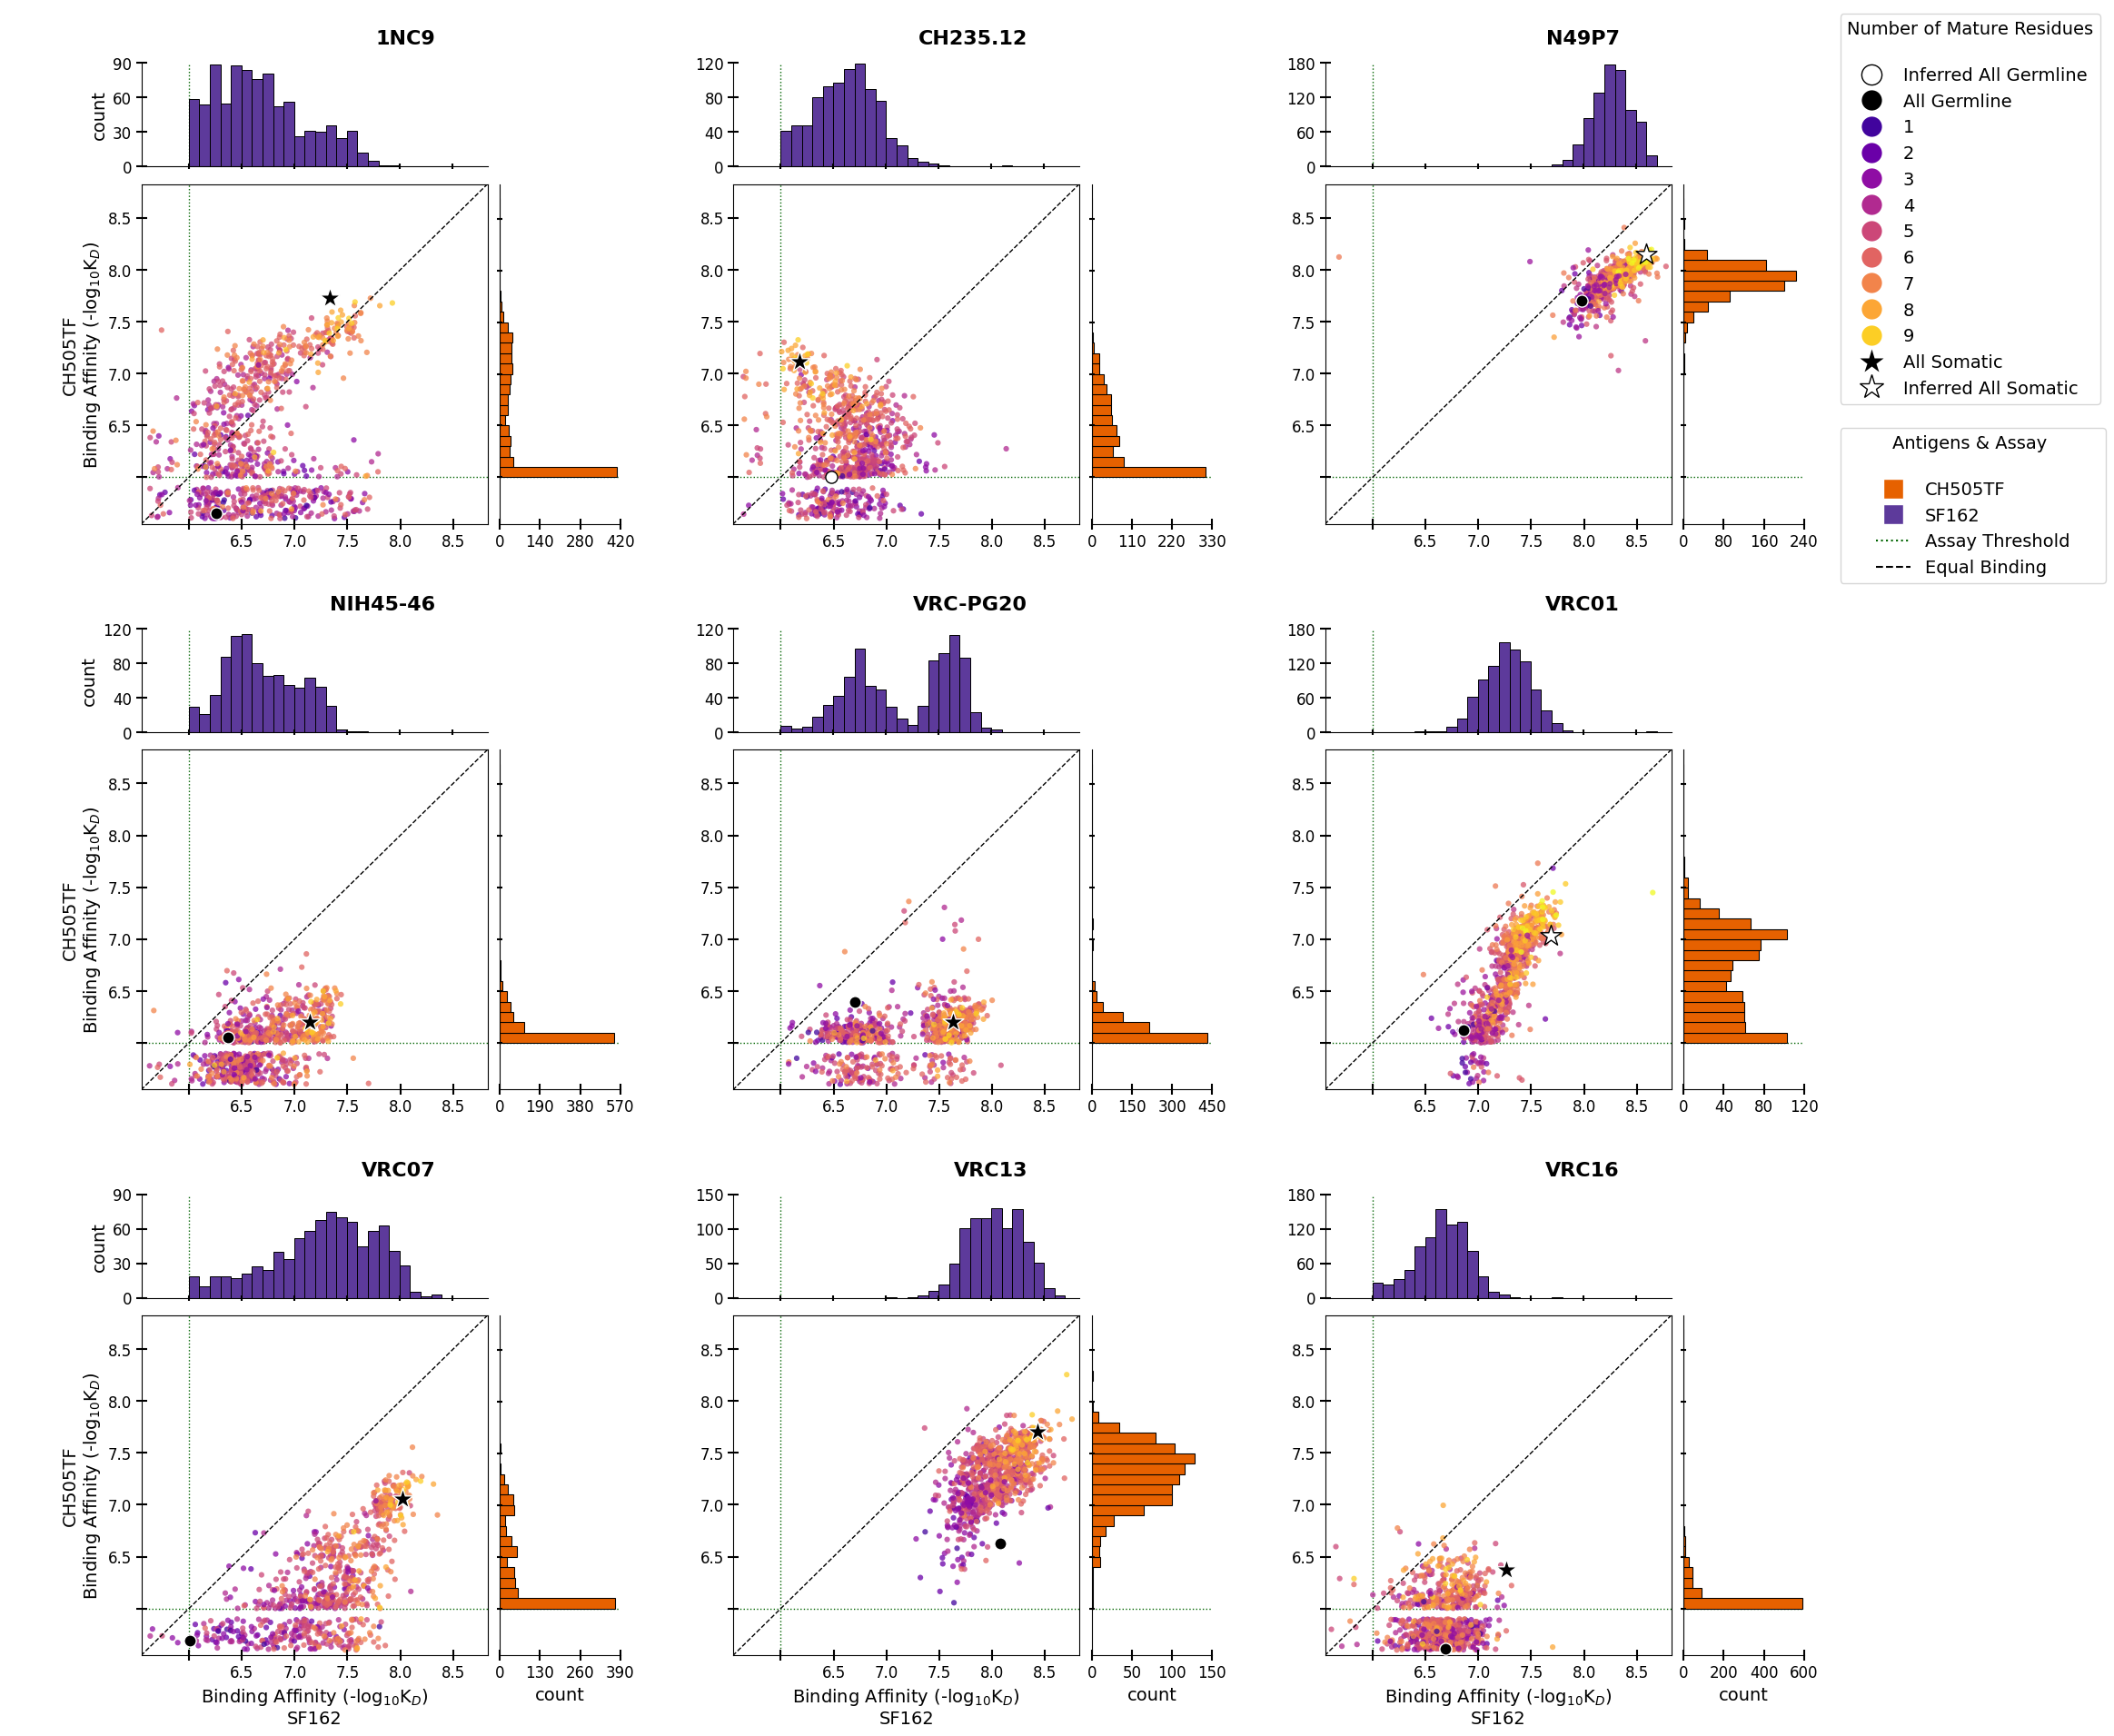

In [ ]:
## store data to be plotted in a dictionary with banb names as keys
kds_wide_dict = {}
for bnab in kds_dict_rep_avg.keys():
  df_wide = base_df_gen(bnab)
  df_wide = jitter_floor(df_wide)
  kds_wide_dict[bnab] = df_wide

# --- helper: build exactly 3 tick locations, all multiples of 10, ---
# --- that comfortably span the max bin height of a given subplot  ---
def get_count_ticks(max_val):
    # smallest multiple-of-10 "half-step" that covers half the max value
    step = max(10, int(np.ceil((max_val / 3) / 10.0)) * 10)
    return [0, step, 2 * step,3 * step]

# make plot
fig, intro_fig = plt.subplots( 6,9, figsize=(20, 19), width_ratios = [.3,2.3,.8,.3,2.3,.8,0.3,2.3,.8], height_ratios= [.7,2.3,.7,2.3,.7,2.3], layout= 'constrained'  )
ax_flatten = intro_fig.flatten()

# build hist axes list
hist_axis_top = []
hist_axis_right = []
scatter_axis = []
no_plot_axis = []
for i in range(3):
  no_plot_axis.extend([x+(i*18) for x in [0,2,3,5,6,8]])
  no_plot_axis.extend([x+(i*18) for x in [9,12,15]])
  hist_axis_top.extend([x+(i*18) for x in [1,4,7]])
  hist_axis_right.extend([x+(i*18) for x in [11,14,17]])
  scatter_axis.extend([x+(i*18) for x in [10,13,16]])

for non_plot_graphs in no_plot_axis:
  ax_flatten[non_plot_graphs].axis('off')

# assign hist axes to antibody
top_axis_antigen = 'SF162'
right_axis_antigen = 'CH505TF'
CH505TF_hist_ylim = 670
SF162_hist_ylim = 190

top_axis_color = '#5D3A9B'
right_axis_color = '#E66100'


# Initialize lists for legend handles and labels
legend_handles = []
legend_labels = []

hist_legend_handles = []
hist_legend_labels = []

# Define colormap and normalization for the 'Number of Mature Residues' legend
norm = Normalize(vmin=0, vmax=10)
cmap = mpl.colormaps.get_cmap('plasma') # Get the 'plasma' colormap

# Generate legend handles and labels for 'Number of Mature Residues'
## wt g inferred
legend_handles.append(Line2D([0], [0], linestyle='none', marker='o', alpha=1, markersize= 16, markerfacecolor = 'none',markeredgecolor= 'k'))
legend_labels.append('Inferred All Germline')
## wt g legend
legend_handles.append(Line2D([0], [0], linestyle='none', marker='o', alpha=1, markersize=16, markerfacecolor='k',markeredgecolor= 'none'))
legend_labels.append('All Germline')

for i in range(1,10): # For values 1 through 9, 0 and 10 marked separately
    color = cmap(norm(i))
    legend_handles.append(Line2D([0], [0], linestyle='none', marker='o', alpha=1, markersize=16, markerfacecolor=color,markeredgecolor= 'none'))
    legend_labels.append(str(i))

## all somatic legened
legend_handles.append(Line2D([0], [0], linestyle='none', marker='*', alpha=1, markersize=20, markerfacecolor='k',markeredgecolor = 'none'))
legend_labels.append('All Somatic')
## Inferred Somatic Legend
legend_handles.append(Line2D([0], [0], linestyle='none', marker='*', alpha=1, markersize= 20, markerfacecolor = 'none',markeredgecolor= 'k'))
legend_labels.append('Inferred All Somatic')


# Add a text label for antigens and dotted lines
hist_handles = [Line2D([0], [0], linestyle='none', marker='s', alpha=1, markersize=16, markerfacecolor= right_axis_color,markeredgecolor= 'white'),
                Line2D([0], [0], linestyle='none', marker='s', alpha=1, markersize=16, markerfacecolor= top_axis_color,markeredgecolor= 'white'),
                Line2D([0], [0], linestyle=':', marker='s', alpha=1, markersize=0, color = 'darkgreen'),
                Line2D([0], [0], linestyle='--', marker='s', alpha=1, markersize=0, color = 'k')]
hist_labels = [ 'CH505TF', 'SF162', 'Assay Threshold', 'Equal Binding']

for handles, labels in zip(hist_handles,hist_labels):
  hist_legend_handles.append(handles)
  hist_legend_labels.append(labels)


#determine max_value
global_max_val = 0
for df in kds_dict_rep_avg.values():
  temp_max = np.max(df['nlog10_Kd'])
  if temp_max > global_max_val:
    global_max_val = temp_max

# shared bin edges used by both marginal histograms
count_bins = np.arange(6, global_max_val, .1)

#######------------------------########
#       Scatter Plot
#######------------------------########
for axes, bnab, df_wide in zip(scatter_axis, kds_wide_dict.keys(), kds_wide_dict.values()):
  sns.scatterplot(ax = ax_flatten[axes], data = df_wide, x = top_axis_antigen, y = right_axis_antigen,
                  hue = 'Number of Mature Residues', palette = cmap, edgecolor = 'none', s = 20,
                  alpha = .75,legend=False) # Set legend=False here

  ax_flatten[axes].plot([5.5,global_max_val+.05],[5.5,global_max_val+.05], linewidth = 1, linestyle = '--', color = 'k')
  ax_flatten[axes].axhline(y = 6, linewidth = 1, linestyle = ':', color = 'darkgreen', zorder = 0.5)
  ax_flatten[axes].axvline(x = 6, linewidth = 1, linestyle = ':', color = 'darkgreen', zorder = 0.5, label = 'assay threshold')
  ax_flatten[axes].set_xlim(left = 5.55, right = global_max_val+.05)
  ax_flatten[axes].set_ylim(bottom = 5.55, top = global_max_val+.05)
  # Generate numerical tick locations
  x_tick_locations = np.arange(6, global_max_val, .5)
  y_tick_locations = np.arange(6, global_max_val, .5)
  # Generate custom tick labels
  x_tick_labels = [f' ' if x == 6.0 else str(x) for x in x_tick_locations]
  y_tick_labels = [f' ' if x == 6.0 else str(x) for x in y_tick_locations]

  ax_flatten[axes].set_xticks(x_tick_locations)
  ax_flatten[axes].set_xticklabels(x_tick_labels)
  ax_flatten[axes].set_yticks(y_tick_locations)
  ax_flatten[axes].set_yticklabels(y_tick_labels)

  if axes not in scatter_axis[-3:]:
    ax_flatten[axes].set_xlabel('\n', color = 'white',fontsize = 5)
  else:
    ax_flatten[axes].set_xlabel(f'Binding Affinity (-log$_1$$_0$K$_D$)\n{top_axis_antigen}', fontsize = 14)
  if axes in [10,28,46]:
    ax_flatten[axes].set_ylabel(f'{right_axis_antigen}\nBinding Affinity (-log$_1$$_0$K$_D$)', fontsize = 14)
  else:
    ax_flatten[axes].set_ylabel('\n', color = 'white',fontsize = 5)

  ### Plot WT Germline and WT Somatic
  # Plot Germline WT (0 mature residues)
  germline_wt_data = df_wide[df_wide['Number of Mature Residues'] == 0].reset_index()

  ax_flatten[axes].scatter(y = germline_wt_data[right_axis_antigen], x = germline_wt_data[top_axis_antigen],
            color = 'k', marker='o', s=90, label='Germline WT', zorder=3, edgecolors = 'white', linewidth = 1)

  germline_wt_data.dropna(inplace= True)
  if len(germline_wt_data) == 0:
    # call tobit
    CH_tobit_df = CH_all_dict[bnab]; SF_tobit_df = SF_all_dict[bnab]
    CH_tobit_df = CH_tobit_df[CH_tobit_df['genotype_tokens'] == 10*'G'].copy()
    SF_tobit_df = SF_tobit_df[SF_tobit_df['genotype_tokens'] == 10*'G'].copy()
    if top_axis_antigen == 'SF162':
      ax_flatten[axes].scatter(x = SF_tobit_df['predicted_kd_full'], y = CH_tobit_df['predicted_kd_full'],
                marker='o', facecolors = 'white', edgecolors = 'k', linewidth = 1, s=90, zorder=3)

    elif top_axis_antigen == 'CH505TF':
      ax_flatten[axes].scatter(y = SF_tobit_df['predicted_kd_full'], x = CH_tobit_df['predicted_kd_full'],
                marker='o', facecolors = 'white', edgecolors = 'k', linewidth = 1, s=90, zorder=3)



  # Plot Full Somatic (10 mature residues)
  full_somatic_wt_data = df_wide[df_wide['Number of Mature Residues'] == 10]

  ax_flatten[axes].scatter(y = full_somatic_wt_data[right_axis_antigen], x = full_somatic_wt_data[top_axis_antigen],
            color = 'k',edgecolors = 'white', linewidth = 1,  marker='*', s=300, label='Full Somatic WT', zorder=3)
  ax_flatten[axes].tick_params(labelsize = 12,length=8, width=1.5,direction = 'inout')

  #### plot inferred
  if len(full_somatic_wt_data) == 0:
    # call tobit
    CH_tobit_df = CH_all_dict[bnab]; SF_tobit_df = SF_all_dict[bnab]
    CH_tobit_df = CH_tobit_df[CH_tobit_df['genotype_tokens'] == 10*'M'].copy()
    SF_tobit_df = SF_tobit_df[SF_tobit_df['genotype_tokens'] == 10*'M'].copy()
    if top_axis_antigen == 'SF162':
      ax_flatten[axes].scatter(x = SF_tobit_df['predicted_kd_full'], y = CH_tobit_df['predicted_kd_full'],
                marker='*', facecolors = 'white', edgecolors = 'k', linewidth = 1, s=300, zorder=3)

    elif top_axis_antigen == 'CH505TF':
      ax_flatten[axes].scatter(y = SF_tobit_df['predicted_kd_full'], x = CH_tobit_df['predicted_kd_full'],
                marker='*', facecolors = 'white', edgecolors = 'k', linewidth = 1, s=300, zorder=3)


#######------------------------########
#       Hist Plot
#######------------------------########

### Right Axis
right_axis_xlim = CH505TF_hist_ylim
for axes, bnab, kds_df in zip(hist_axis_right, kds_dict_rep_avg.keys(),kds_dict_rep_avg.values()):

  plotted_right_df = kds_df[kds_df['antigen'] == right_axis_antigen]

  sns.histplot(ax = ax_flatten[axes], data = plotted_right_df, y= 'nlog10_Kd',color = right_axis_color,
               bins = np.arange( 6,global_max_val,.1),alpha = 1, legend=False) # Set legend=False here as well

  ax_flatten[axes].set_yticks(np.arange(6,global_max_val,.5))
  ax_flatten[axes].set_ylim(bottom = 5.55, top = None)
  # ax_flatten[axes].set_xlim(left = None, right = right_axis_xlim)
  ax_flatten[axes].set(ylabel = None)
  ax_flatten[axes].axhline(y= 6, linestyle = ':', linewidth = 1, color = 'darkgreen',zorder= 0.5)
  ax_flatten[axes].tick_params(axis = 'y', labelleft = False,  length =5, width = 1.5,direction = 'inout')
  ax_flatten[axes].tick_params(axis = 'x', direction = 'inout',labelsize =12,length = 8, width = 1.5)


  # --- force exactly 3 count ticks (multiples of 10) on the x-axis ---
  right_counts, _ = np.histogram(plotted_right_df['nlog10_Kd'].dropna(), bins=count_bins)
  right_max_count = right_counts.max() if len(right_counts) else 0
  right_ticks = get_count_ticks(right_max_count)
  ax_flatten[axes].set_xticks(right_ticks)
  ax_flatten[axes].set_xlim(left=0, right=right_ticks[-1])

  if axes in hist_axis_right[-3:]:
    ax_flatten[axes].set_xlabel('count',fontsize = 14)
  else:
    ax_flatten[axes].set_xlabel('\n.', color = 'white',fontsize = 5)

  # despine
  ax_flatten[axes].spines['right'].set_visible(False)
  ax_flatten[axes].spines['top'].set_visible(False)

### Top Axis
left_axis_ylim = SF162_hist_ylim
for axes, bnab, kds_df in zip(hist_axis_top, kds_dict_rep_avg.keys(),kds_dict_rep_avg.values()):


  plotted_right_df = kds_df[kds_df['antigen'] == top_axis_antigen]

  sns.histplot(ax = ax_flatten[axes], data = plotted_right_df, x= 'nlog10_Kd',color = top_axis_color,
               bins = np.arange(6,global_max_val,.1),alpha = 1, legend=False) # Set legend=False here as well

  ax_flatten[axes].set_xticks(np.arange(6,global_max_val,.5))
  ax_flatten[axes].set_xlim(left = 5.55, right = None)
  # ax_flatten[axes].set_ylim(bottom = None, top = left_axis_ylim)

  ax_flatten[axes].set(xlabel = None)
  ax_flatten[axes].axvline(x= 6, linestyle = ':', linewidth = 1, zorder= 0.5, color = 'darkgreen')
  ax_flatten[axes].tick_params(axis = 'x', labelbottom = False, length =5, width = 1.5,direction = 'inout')
  ax_flatten[axes].tick_params(axis = 'y', direction = 'inout',labelsize =12,length = 8, width = 1.5)

  ax_flatten[axes].set_title(f'\n{bnab}', x=.85, ha="right", fontsize = 16, weight = 'bold', pad = 15  )


  # --- force exactly 3 count ticks (multiples of 10) on the y-axis ---
  top_counts, _ = np.histogram(plotted_right_df['nlog10_Kd'].dropna(), bins=count_bins)
  top_max_count = top_counts.max() if len(top_counts) else 0
  top_ticks = get_count_ticks(top_max_count)
  ax_flatten[axes].set_yticks(top_ticks)
  ax_flatten[axes].set_ylim(bottom=0, top=top_ticks[-1])



  if axes in [1,19,37]:
    ax_flatten[axes].set_ylabel('count',color = 'k',fontsize = 14)
  else:
    ax_flatten[axes].set_ylabel('\n', color = 'white',fontsize = 5)

  ax_flatten[axes].spines['top'].set_visible(False)
  ax_flatten[axes].spines['right'].set_visible(False)

# Add the single figure-level legend
fig.legend(fontsize=14,handles=legend_handles, labels=legend_labels, title='Number of Mature Residues\n', loc='upper left', bbox_to_anchor=(1.005, 1), title_fontsize=14)
fig.legend(fontsize=14,handles=hist_legend_handles, labels=hist_legend_labels, title='        Antigens & Assay         \n', loc='upper left', bbox_to_anchor=(1.005, .76), title_fontsize=14)


save_figure("updated_axes_histscatt")
plt.show()

## Cmap

In [ ]:
#### Generate Data
def token_kds(bnab: str,antigen: str = None):
  '''''
  Creates a Dataframe with the Gtype +RAW Kd

  bnab = 'bnab name'

  antigen = 'CH505TF' or 'SF162' depending on which antigen you want

  '''''
  df = kds_dict_rep_avg[bnab]
  if antigen == 'CH505TF':
    df = df[df['antigen'] == antigen].copy()
  elif antigen == 'SF162':
    df = df[df['antigen'] == antigen].copy()
  else:
    pass

  df['genotype_tokens'] = df[['site_0','site_1','site_2','site_3','site_4','site_5','site_6','site_7','site_8','site_9']].agg(''.join, axis=1)
  df['n_somatic'] = ((df['site_0'] == 'M').astype(int) + (df['site_1'] == 'M').astype(int) + (df['site_2'] == 'M').astype(int) +
                               (df['site_3'] == 'M').astype(int) + (df['site_4'] == 'M').astype(int) + (df['site_5'] == 'M').astype(int) +
                               (df['site_6'] == 'M').astype(int) + (df['site_7'] == 'M').astype(int) + (df['site_8'] == 'M').astype(int) +
                               (df['site_9'] == 'M').astype(int) )


  return df

kds_token_dict_rep_avg = {}
for bnab in kds_dict_rep_avg.keys():
  for antigen in ['CH505TF','SF162']:

    kds_token_dict_rep_avg[f'{bnab}_{antigen}'] = token_kds(bnab, antigen = antigen)


site_effect_raw_dict = { }
raw_split_dict = {}
site_effect = pd.DataFrame({
    'bnAb': kds_token_dict_rep_avg.keys()})
site_effect = site_effect.assign(
    site_0 = np.nan, site_1 = np.nan, site_2 = np.nan,
    site_3 = np.nan, site_4 = np.nan, site_5 = np.nan,
    site_6 = np.nan, site_7 = np.nan, site_8 = np.nan,
    site_9 = np.nan)

p_values_df = site_effect.copy()

for bnab_ant, df_antigen in kds_token_dict_rep_avg.items():
    antigen = bnab_ant.split('_')[1]
    bnab = bnab_ant.split('_')[0]
    for s in range(10): # Loop through each site
      # Filter for germline variants at the current site 's'
      germline_s_df = df_antigen[df_antigen[f'site_{s}'] == 'G'].copy()

      if not germline_s_df.empty:
          # Create a new column with the genotype_tokens if site 's' was mature
          germline_s_df['mature_genotype_token'] = germline_s_df['genotype_tokens'].apply(
              lambda gtype: gtype[:s] + 'M' + gtype[s+1:]
          )

          # Merge to get the nlog10_Kd of the corresponding mature variant
          kds_merged_df = germline_s_df.merge(
              df_antigen[['genotype_tokens', 'nlog10_Kd']],
              left_on='mature_genotype_token',
              right_on='genotype_tokens',
              how='left',
              suffixes=('_germline', '_mature')
          )

          # Calculate the difference: mature_Kd - germline_Kd
          # This is the effect of changing site 's' from G to M
          kds_merged_df['difference'] = kds_merged_df['nlog10_Kd_mature'] - kds_merged_df['nlog10_Kd_germline']

          site_effect_raw_dict[f'{bnab}_{antigen}_site_{s}'] = kds_merged_df['difference'].values

          raw_split_dict[f'{bnab}_{antigen}_site_{s}'] = np.array([kds_merged_df['nlog10_Kd_mature'].values,kds_merged_df['nlog10_Kd_germline'].values])

          # Calculate the average effect
          bg_avg_effect = kds_merged_df['difference'].mean()
          # Compute the p_value of the effect (raw data delta kd t test)
          t, p_value = sp.stats.ttest_rel(kds_merged_df['nlog10_Kd_mature'].values, kds_merged_df['nlog10_Kd_germline'].values,nan_policy= 'omit')

      else:
          bg_avg_effect = np.nan # If no germline variants at this site, effect is NaN
          p_value = np.nan


      # Update the site_effect DataFrame
      site_effect_row_idx = site_effect.index[site_effect['bnAb'] == bnab_ant].tolist()
      if site_effect_row_idx:
          site_effect.loc[site_effect_row_idx[0], f'site_{s}'] = bg_avg_effect
          p_values_df.loc[site_effect_row_idx[0], f'site_{s}'] = p_value

site_effect['antigen'] = site_effect['bnAb'].apply(lambda x: x.split('_')[1])
site_effect['bnAb'] = site_effect['bnAb'].apply(lambda x: x.split('_')[0])

# raw data p-value (not Cohen's D)
p_values_df['antigen'] = p_values_df['bnAb'].apply(lambda x: x.split('_')[1])
p_values_df['bnAb'] = p_values_df['bnAb'].apply(lambda x: x.split('_')[0])


p_values_arr = p_values_df.iloc[:,1:-1].values.flatten()
reject, adjusted_pvalues, _, _ = multipletests(p_values_arr, alpha = 0.05, method = 'fdr_bh')
adjusted_pvalues = adjusted_pvalues.reshape(18,10)
p_values_df.iloc[:,1:-1] = adjusted_pvalues
p_values_df.to_csv('BH_corrected_pval_new_kds.csv')

In [ ]:
p_val_df_new = p_values_df.copy()

p_val_df_new_CH = p_val_df_new[p_val_df_new['antigen'] == 'CH505TF'].copy()
p_val_df_new_SF = p_val_df_new[p_val_df_new['antigen'] == 'SF162'].copy()

p_val_df_new_SF = pd.melt(p_val_df_new_SF, id_vars= 'bnAb', value_vars = [f'site_{i}' for i in range(10)], var_name= 'site', value_name='p_value')
p_val_df_new_SF.sort_values(by = ['bnAb','site'], inplace = True)

p_val_df_new_CH = pd.melt(p_val_df_new_CH, id_vars= 'bnAb', value_vars = [f'site_{i}' for i in range(10)], var_name= 'site', value_name='p_value')
p_val_df_new_CH.sort_values(by = ['bnAb','site'], inplace = True)

p_values_merged_df = p_val_df_new_CH.merge(p_val_df_new_SF, on = ['bnAb', 'site'], suffixes = ('_CH505TF','_SF162'))
p_values_merged_df.columns = ['bnab',	'site',	'CH505TF','SF162']

-0.3109364154126908 0.8763504058759573
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>
<Axes.ArtistList of 10 texts>


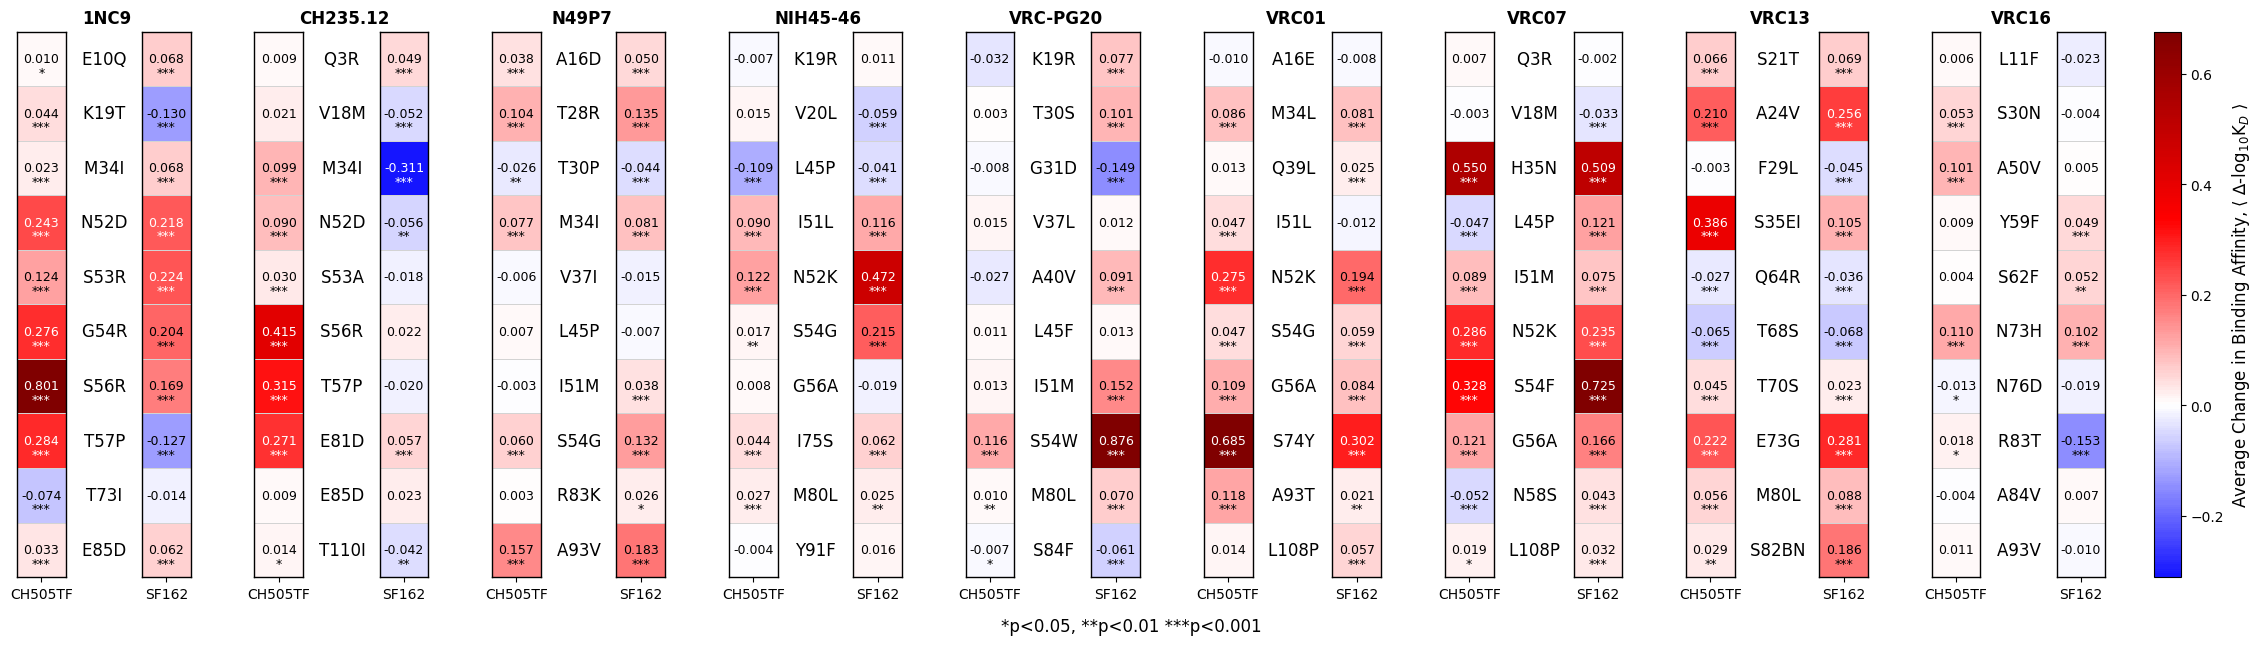

In [ ]:
def get_contrast_color(value, norm, cmap, thresh=0.55):
    """Return 'white' or 'black' depending on how dark/light the cell color is."""
    if pd.isna(value):
        return 'black'
    r, g, b, _ = cmap(norm(value))
    luminance = 0.299*r + 0.587*g + 0.114*b
    return 'white' if luminance < thresh else 'black'


# call list of antibodies
unique_bnAbs = site_effect['bnAb'].unique()

# Calculate the global min and max for consistent colormap scaling across all heatmaps
all_site_effect_values = site_effect.filter(regex='site_\\d').values
global_min_val = np.nanmin(all_site_effect_values)
global_max_val = np.nanmax(all_site_effect_values)
print(global_min_val, global_max_val) # these are the lowest and highest background average ∆Kd

global_max_val = global_max_val - .2 # force down to improve color resolution
# initialize colormap for the whole plot
center = 0
vrange = max(global_max_val - center, center - global_min_val)
center_normalize = Normalize(center - vrange, center + vrange)
cmin, cmax = center_normalize([global_min_val, global_max_val])
cell_norm = Normalize(vmin=global_min_val, vmax=global_max_val) # normalization for coloring asterisk

base_cmap = plt.get_cmap('seismic')
trimmed_colors = base_cmap(np.linspace(cmin, cmax, 256))
trimmed_cmap = mpl.colors.ListedColormap(trimmed_colors)

# Create a figure with 1 row and `len(unique_bnAbs)` columns
fig, axes = plt.subplots(1, 4*len(unique_bnAbs), figsize=(len(unique_bnAbs) * 2.5, 6), width_ratios= len(unique_bnAbs)*[1.1,.6,1.1,.9],layout='constrained')

# Handle the case where there's only one subplot, axes might not be an array
for i, bnab in enumerate(unique_bnAbs):
    #assign axes
    CHax = axes[i*4]
    SFax = axes[2+i*4]
    labelax = axes[1+i*4]
    hide_axis = axes[3+i*4]
    hide_axis.axis('off')

    #call p_values (currently using cohen's d p_values)
    bnab_pval = p_values_updated[p_values_updated['bnAb'] == bnab].copy()

    # Retrieve the meta_df for the current bnAb
    current_meta_df = meta_dict[bnab]
    # Generate the label mapping using the mutation_convert_label function
    convert_label = mutation_convert_label(current_meta_df)

    # Filter data for the current bnAb
    bnab_data = site_effect[site_effect['bnAb'] == bnab].copy()

    # Melt the site columns into 'site_name' and 'effect' columns
    melted_data = bnab_data.melt(id_vars=['antigen'], value_vars=[col for col in bnab_data.columns if 'site_' in col],
                                 var_name='site_name', value_name='effect')

    # Apply the label conversion to the site names
    melted_data['site_name'] = melted_data['site_name'].apply(lambda x: convert_label.get(x, x))
    # Pivot the table to have sites as rows and antigens as columns
    heatmap_data = melted_data.pivot(index='site_name', columns='antigen', values='effect')
    # Ensure the order of sites is correct (site_0 to site_9), using the custom labels directly
    site_order_raw = [f'site_{j}' for j in range(10)]
    custom_yticklabels_ordered = [convert_label.get(s, s) for s in site_order_raw]
    heatmap_data = heatmap_data.reindex(custom_yticklabels_ordered).iloc[::-1]

    # Plot the heatmap with cbar=False for individual subplots
    # NOTE: cmap is now the pre-trimmed colormap, and we drop `center=0`
    # since the trimming already encodes the centering; vmin/vmax stay
    # as the true global values so the linear Normalize is accurate.
    sns.heatmap(heatmap_data[['CH505TF']], ax=CHax, cmap=trimmed_cmap, cbar=False, linewidths=0.5, linecolor='lightgrey',
                vmin=global_min_val, vmax=global_max_val,
                fmt=".3f", annot=True, annot_kws={"fontsize":9})

    CH_values = heatmap_data['CH505TF'].values
    CH_colors = [get_contrast_color(v, cell_norm, trimmed_cmap) for v in CH_values]
    for txt, color in zip(CHax.texts, CH_colors):
        txt.set_color(color)
    print(CHax.texts)


    sns.heatmap(heatmap_data[['SF162']], ax=SFax, cmap=trimmed_cmap, cbar=False, linewidths=0.5, linecolor='lightgrey',
                vmin=global_min_val, vmax=global_max_val,
                fmt=".3f", annot=True, annot_kws={"fontsize":9})

    SF_values = heatmap_data['SF162'].values
    SF_colors = [get_contrast_color(v, cell_norm, trimmed_cmap) for v in SF_values]
    for txt, color in zip(SFax.texts, SF_colors):
      txt.set_color(color)
    print(SFax.texts)


    CHax.set(xlabel = '',ylabel = '',xlim = (0,1), ylim  = (0,10))
    SFax.set(xlabel = '',ylabel = '',xlim = (0,1), ylim  = (0,10))
    for ax in [CHax,SFax]:
      ax.tick_params(axis='y', labelsize=0, length=0)
      ax.set_yticklabels([])
      for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_linewidth(1)
    labelax.set(xlim = (0,5), ylim  = (0,10))
    labelax.set_title(f'{bnab}', fontsize=12, fontweight='bold', ha = 'center',x = 0)
    labelax.axis('off')

    custom_yticklabels_ordered.reverse()
    for order, site in enumerate(custom_yticklabels_ordered):
      labelax.text(0,order+.5, f'{site} ',fontsize = 12, color = 'k', ha = 'center', va = 'center')

    ## generate asterisks for pvalue
    CH_pval = list(bnab_pval['CH505TF'].values)
    SF_pval = list(bnab_pval['SF162'].values)

    CH_pval.reverse(); SF_pval.reverse()

    for order, CH_val, SF_val, CH_color, SF_color in zip(
        range(len(CH_pval)), CH_pval, SF_pval, CH_colors, SF_colors):
      if CH_val < 0.001:
        CHax.text(0.5,order+.25, '***',fontsize = 9, color = CH_color, ha = 'center', va = 'center')
      elif CH_val < 0.01:
        CHax.text(0.5,order+.25, '**',fontsize = 9, color = CH_color, ha = 'center', va = 'center')
      elif CH_val < 0.05:
        CHax.text(0.5,order+.25, '*',fontsize = 9, color = CH_color, ha = 'center', va = 'center')
      else:
        pass

      if SF_val < 0.001:
        SFax.text(0.5,order+.25, '***',fontsize = 9, color = SF_color, ha = 'center', va = 'center')
      elif SF_val < 0.01:
        SFax.text(0.5,order+.25, '**',fontsize = 9, color = SF_color, ha = 'center', va = 'center')
      elif SF_val < 0.05:
        SFax.text(0.5,order+.25, '*',fontsize = 9, color = SF_color, ha = 'center', va = 'center')
      else:
        pass



# --- Colorbar: plain linear Normalize over the SAME trimmed cmap ---
# used in the heatmaps. Because this is linear (not TwoSlopeNorm),
# the region above 0 will naturally occupy a larger share of the bar
# whenever global_max_val > abs(global_min_val), matching the heatmap.
sm = plt.cm.ScalarMappable(cmap=trimmed_cmap, norm=Normalize(vmin=global_min_val, vmax=global_max_val))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), orientation='vertical', fraction=0.02, pad=0.0)
cbar.set_label(r'Average Change in Binding Affinity, $\langle$ ∆-log$_1$$_0$K$_D$ $\rangle$', fontsize=12)

plt.suptitle('*p<0.05, **p<0.01 ***p<0.001', fontsize = 12, x = 0.5, y = -.02, va = 'top')

save_figure("supplement_fig_s1")

plt.show()